# Fine-tuned photovoltaic cell defect detection

The objective is **more than 92% ordinary test accuracy** on the same 656 ELPV cells used in the earlier notebook. The binary target is defective for the 2/3 and 1 confidence levels. All four confidence levels remain in the test evaluation. The paper reports 90.13% for mean class recall, so the results also include the equivalent metric, balanced accuracy. [Ebied et al., Scientific Reports](https://doi.org/10.1038/s41598-025-14478-y)

## Recorded result

The full-development refit blend had the highest observed ordinary accuracy at **91.92%** (603/656 cells), with **87.74% balanced accuracy**. It used the selected two-backbone ensemble with ordinal heads and texture. This exploratory result fell short of the greater-than-92% ordinary-accuracy target. The table below reports each operating point.

## Run the notebook

Use a GPU-enabled Python kernel with PyTorch, torchvision, NumPy, pandas, Pillow, SciPy, scikit-learn, and Matplotlib. Install missing packages in the notebook kernel with `%pip install torch torchvision numpy pandas pillow scipy scikit-learn matplotlib`. The cross-validation and specialist fine-tuning runs benefit from CUDA.

Place `elpv-dataset-master.zip` beside the notebook, on your Desktop, or in `/content` on Colab. You can edit `DATASET` in the setup cell or set the `ELPV_DATASET` environment variable to the archive or extracted dataset directory. The ImageNet weights download on first use. For offline use, set `ELPV_CONVNEXT_WEIGHTS` and `ELPV_EFFICIENTNET_WEIGHTS` to the official local checkpoint files.

Run all cells to reproduce the experiment. The training cell saves each completed fold under `elpv_checkpoints` for reuse when restarted. GPU kernels and software versions can cause small run-to-run differences.

## Dataset and evaluation split

The outer 25% test split is the same as in the earlier notebook. The remaining 1,968 cells form the development set. Each development image receives predictions from models trained on the other three development folds. Exact duplicate image files stay together. The release omits panel IDs, so metrics describe a cell-level split. The earlier experiments already examined this test split, making this follow-up exploratory. [ELPV dataset](https://github.com/zae-bayern/elpv-dataset)

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import hashlib
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.nn import functional as F
from torchvision import models

DATASET = Path(os.environ.get("ELPV_DATASET", "elpv-dataset-master.zip")).expanduser()
if not DATASET.exists() and "ELPV_DATASET" not in os.environ:
    DATASET = next((p for p in (
        Path.home() / "Desktop" / DATASET.name,
        Path("/content") / DATASET.name,
    ) if p.exists()), DATASET)

SEED = 42
TEST_FRACTION = 0.25
VALIDATION_FRACTION_OF_DEVELOPMENT = 0.20
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.set_float32_matmul_precision("high")
if DEVICE.type == "cuda":
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = False


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def read_elpv(source):
    if not source.exists():
        raise FileNotFoundError(f"Place the ELPV ZIP beside the notebook or set ELPV_DATASET. Tried {source.resolve()}")
    if source.is_dir():
        candidates = sorted(source.rglob("labels.csv"))
        if len(candidates) != 1:
            raise ValueError(f"Expected one labels.csv under {source}, found {len(candidates)}.")
        labels = candidates[0]
        rows = [line.split() for line in labels.read_text(encoding="utf-8").splitlines() if line.strip()]
        raw_images = [(labels.parent / name).read_bytes() for name, _, _ in rows]
    else:
        with ZipFile(source) as archive:
            candidates = [name for name in archive.namelist() if name.split("/")[-1] == "labels.csv"]
            if len(candidates) != 1:
                raise ValueError(f"Expected one labels.csv in {source}, found {len(candidates)}.")
            labels = candidates[0]
            prefix = labels.rpartition("/")[0]
            rows = [line.split() for line in archive.read(labels).decode().splitlines() if line.strip()]
            raw_images = [archive.read(f"{prefix}/{name}" if prefix else name) for name, _, _ in rows]
    frame = pd.DataFrame(rows, columns=["image", "defect_probability", "cell_type"])
    frame["defect_probability"] = frame["defect_probability"].astype(float)
    levels = np.array([0.0, 1 / 3, 2 / 3, 1.0])
    distance = abs(frame["defect_probability"].to_numpy()[:, None] - levels)
    if not np.all(distance.min(axis=1) < 0.01) or not frame["cell_type"].isin(["mono", "poly"]).all():
        raise ValueError("Unexpected ELPV probability or cell type.")
    frame["level"] = distance.argmin(axis=1)
    frame["stratum"] = 2 * frame["level"] + frame["cell_type"].eq("poly").astype(int)
    frame["defective"] = (frame["level"] >= 2).astype(int)
    frame["image_sha256"] = [hashlib.sha256(raw).hexdigest() for raw in raw_images]
    if len(frame) != 2624 or not frame["image"].is_unique:
        raise ValueError("This experiment expects the complete 2,624-cell ELPV release.")
    return frame, raw_images


def split_elpv(frame):
    # Use a representative per exact duplicate group when sampling the holdouts.
    unique = frame.drop_duplicates("image_sha256")
    dev, test = train_test_split(
        unique.index.to_numpy(), test_size=TEST_FRACTION, random_state=SEED,
        stratify=unique["stratum"],
    )
    train, val = train_test_split(
        dev, test_size=VALIDATION_FRACTION_OF_DEVELOPMENT, random_state=SEED,
        stratify=frame.loc[dev, "stratum"],
    )
    split_by_hash = {
        frame.at[i, "image_sha256"]: name
        for name, indices in (("train", train), ("validation", val), ("test", test))
        for i in indices
    }
    assigned = frame["image_sha256"].map(split_by_hash)
    return tuple(np.flatnonzero(assigned.eq(name)) for name in ("train", "validation", "test"))


def resized_tensor(raw_images, size):
    data = np.empty((len(raw_images), 1, size, size), dtype=np.uint8)
    for i, raw in enumerate(raw_images):
        with Image.open(BytesIO(raw)) as image:
            data[i, 0] = np.asarray(image.convert("L").resize((size, size), Image.Resampling.BILINEAR))
    return torch.from_numpy(data)


frame, raw_images = read_elpv(DATASET)
train_idx, val_idx, test_idx = split_elpv(frame)
label_values = frame["level"].to_numpy()
truth = frame["defective"].to_numpy()
print(f"ELPV on {DEVICE} | train {len(train_idx)} | validation {len(val_idx)} | test {len(test_idx)}")

ELPV on cuda | train 1574 | validation 394 | test 656


## Fine-tuning models

ConvNeXt-Tiny runs at 252 × 252 and EfficientNetV2-S at 224 × 224. Each starts from ImageNet weights. The earliest stages stay frozen while later layers and the prediction head train. The head combines global average and spatial max pooling with the supplied mono/poly tag. It learns a softened binary target and the three cumulative ordinal targets. The final three epoch checkpoints are averaged.

One candidate mixes shared ConvNeXt predictions with technology specialists at weights of 55% and 45%. For each fold, the specialists start from its ConvNeXt checkpoint and adapt the last stage and head using either the monocrystalline or the polycrystalline training cells.

Training applies flips, transposition, and mild brightness jitter. Alternating folds use either globally blended grayscale contrast or additional local contrast to emphasize fine cracks. Inference averages the eight orientation views. Rotations preserve the label and account for vertical or horizontal busbars. [Deitsch et al., ELPV benchmark paper](https://www5.informatik.uni-erlangen.de/Forschung/Publikationen/2019/Deitsch19-ACO.pdf)

In [2]:
def imagenet_input(x):
    mean = x.new_tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = x.new_tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return ((x - mean) / std).contiguous(memory_format=torch.channels_last)


def make_backbone(name):
    if name == "resnet152":
        local = os.environ.get("ELPV_RESNET152_WEIGHTS")
        if local:
            model = models.resnet152(weights=None)
            model.load_state_dict(torch.load(local, map_location="cpu", weights_only=True))
            return model
        return models.resnet152(weights=models.ResNet152_Weights.IMAGENET1K_V1)
    if name == "resnet50":
        return models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    if name == "convnext_tiny":
        local = os.environ.get("ELPV_CONVNEXT_WEIGHTS")
        if local:
            model = models.convnext_tiny(weights=None)
            model.load_state_dict(torch.load(local, map_location="cpu", weights_only=True))
            return model
        return models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
    raise ValueError(f"Unsupported backbone {name!r}.")


def to_model(model):
    return model.to(device=DEVICE, memory_format=torch.channels_last)

In [3]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression

REFINE_SIZE = 252
REFINE_BATCH = 32
REFINE_EPOCHS = 16
SPECIALIST_EPOCHS = 5
REFINE_FOLDS = 4
REFINE_SEED = 726
REFINE_RUN_DIR = Path("elpv_checkpoints")


def refine_input(batch, training, local):
    x = batch.to(DEVICE, dtype=torch.float32).div_(255)
    if training:
        shape = (len(x), 1, 1, 1)
        for dims in ((-1,), (-2,)):
            x = torch.where(torch.rand(shape, device=DEVICE) < 0.5, x.flip(dims), x)
        x = torch.where(torch.rand(shape, device=DEVICE) < 0.5, x.transpose(-2, -1), x)
        gain = torch.empty(shape, device=DEVICE).uniform_(0.85, 1.16)
        bias = torch.empty(shape, device=DEVICE).uniform_(-0.055, 0.055)
        x = (x * gain + bias).clamp(0, 1)
    sd, mean = torch.std_mean(x, (-2, -1), correction=0, keepdim=True)
    normalized = ((x - mean) * (0.195 / sd.clamp_min(0.05)) + 0.5).clamp_(0, 1)
    gray = 0.63 * x + 0.37 * normalized
    if local:
        smooth = F.avg_pool2d(gray, 13, stride=1, padding=6, count_include_pad=False)
        detail = (0.56 + 2.5 * (gray - smooth)).clamp_(0, 1)
        gray = torch.cat([gray, 0.70 * gray + 0.30 * detail, 0.43 * gray + 0.57 * detail], dim=1)
    return imagenet_input(gray)


class RefinedOrdinalNet(nn.Module):
    def __init__(self, architecture, pretrained=True):
        super().__init__()
        if architecture == "convnext":
            backbone = make_backbone("convnext_tiny") if pretrained else models.convnext_tiny(weights=None)
            self.stem = backbone.features[:2]
            self.middle = backbone.features[2:6]
            self.deep = backbone.features[6:]
            channels = 1922
        elif architecture == "efficientnet":
            local_weights = os.environ.get("ELPV_EFFICIENTNET_WEIGHTS") if pretrained else None
            model_weights = models.EfficientNet_V2_S_Weights.DEFAULT if pretrained and not local_weights else None
            backbone = models.efficientnet_v2_s(weights=model_weights)
            if local_weights:
                backbone.load_state_dict(torch.load(local_weights, map_location="cpu", weights_only=True))
            self.stem = backbone.features[:4]
            self.middle = backbone.features[4:6]
            self.deep = backbone.features[6:]
            channels = 2722
        else:
            raise ValueError(f"Unknown architecture {architecture}.")
        self.stem.requires_grad_(False)
        self.head = nn.Sequential(
            nn.LayerNorm(channels), nn.Dropout(0.18), nn.Linear(channels, 384),
            nn.LayerNorm(384), nn.GELU(), nn.Dropout(0.22), nn.Linear(384, 4),
        )

    def forward(self, x, tech):
        self.stem.eval()
        mid = self.middle(self.stem(x))
        deep = self.deep(mid)
        mixed = torch.cat([
            mid.amax(dim=(-2, -1)), deep.mean(dim=(-2, -1)), deep.amax(dim=(-2, -1)),
            F.one_hot(tech, 2).to(deep.dtype),
        ], dim=1)
        return self.head(mixed)


def refine_loss(logits, levels):
    cumulative = (levels[:, None] >= torch.arange(1, 4, device=levels.device)).float()
    soft_binary = logits.new_tensor([0.02, 0.12, 0.88, 0.98]).float()[levels]
    binary = F.binary_cross_entropy_with_logits(logits[:, 0], soft_binary)
    ordinal = F.binary_cross_entropy_with_logits(logits[:, 1:], cumulative)
    return binary + 0.35 * ordinal


def amp_refine():
    return torch.autocast(
        device_type=DEVICE.type, dtype=torch.bfloat16,
        enabled=DEVICE.type == "cuda" and torch.cuda.is_bf16_supported(),
    )


def model_state(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def train_refine(images, levels, types, train, local, seed, architecture, epochs, initial=None):
    seed_everything(seed)
    model = to_model(RefinedOrdinalNet(architecture, pretrained=initial is None))
    groups = [
        {"params": model.middle.parameters(), "lr": 0.00026},
        {"params": model.deep.parameters(), "lr": 0.00038},
        {"params": model.head.parameters(), "lr": 0.00115},
    ]
    if initial is not None:
        model.load_state_dict(initial)
        model.middle.requires_grad_(False)
        groups = [
            {"params": model.deep.parameters(), "lr": 6e-5},
            {"params": model.head.parameters(), "lr": 2.1e-4},
        ]
    optimizer = torch.optim.AdamW(groups, weight_decay=0.025, fused=DEVICE.type == "cuda")
    steps = math.ceil(len(train) / REFINE_BATCH)
    lr = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[g["lr"] for g in groups], epochs=epochs, steps_per_epoch=steps,
        pct_start=0.18, div_factor=10, final_div_factor=45, cycle_momentum=False,
    )
    history = []
    weight_sum = None
    for epoch in range(1, epochs + 1):
        start = time.monotonic()
        model.train()
        if initial is not None:
            model.middle.eval()
        order = train[torch.randperm(len(train)).numpy()]
        total = torch.zeros((), device=DEVICE)
        for batch in np.array_split(order, steps):
            images_in = refine_input(images[batch], training=True, local=local)
            optimizer.zero_grad(set_to_none=True)
            with amp_refine():
                loss = refine_loss(model(images_in, types[batch]), levels[batch])
            loss.backward()
            optimizer.step()
            lr.step()
            total += loss.detach() * len(batch)
        loss_avg = total.item() / len(train)
        if not np.isfinite(loss_avg):
            raise FloatingPointError("Fine-tuning loss became non-finite.")
        history.append({"epoch": epoch, "loss": loss_avg, "seconds": time.monotonic() - start})
        print(f"Epoch {epoch:02d}/{epochs} | loss {loss_avg:.4f} | {history[-1]['seconds']:.1f}s", flush=True)
        if epoch > epochs - 3:
            current = model_state(model)
            if weight_sum is None:
                weight_sum = current
            else:
                for name in weight_sum:
                    if weight_sum[name].is_floating_point():
                        weight_sum[name].add_(current[name])
                    else:
                        weight_sum[name] = current[name]
    count = min(3, epochs)
    return {name: value.div_(count) if value.is_floating_point() else value
            for name, value in weight_sum.items()}, history


@torch.inference_mode()
def score_refine(model, images, types, indices, local):
    model.eval()
    pieces = []
    for batch in np.array_split(indices, math.ceil(len(indices) / REFINE_BATCH)):
        x = refine_input(images[batch], training=False, local=local)
        predictions = []
        with amp_refine():
            for transpose in (False, True):
                view = x.transpose(-2, -1) if transpose else x
                for axes in ((), (-1,), (-2,), (-2, -1)):
                    inp = view.flip(axes) if axes else view
                    result = model(inp.contiguous(memory_format=torch.channels_last), types[batch])
                    predictions.append(result.float())
        probabilities = torch.stack(predictions).sigmoid().mean(dim=0)
        pieces.append(probabilities.cpu().numpy())
    return np.concatenate(pieces)


def refinement_data():
    images = resized_tensor(raw_images, REFINE_SIZE)
    levels = torch.tensor(label_values, dtype=torch.long, device=DEVICE)
    tech_values = frame["cell_type"].eq("poly").to_numpy().astype(np.int64)
    types = torch.as_tensor(tech_values, dtype=torch.long, device=DEVICE)
    dev = np.sort(np.r_[train_idx, val_idx])
    splitter = StratifiedGroupKFold(n_splits=REFINE_FOLDS, shuffle=True, random_state=REFINE_SEED)
    folds = list(splitter.split(dev, frame.loc[dev, "stratum"], frame.loc[dev, "image_sha256"]))
    return images, levels, types, dev, folds


def fit_refinement(images, levels, types, dev, folds, run_dir, architecture="convnext", epochs=REFINE_EPOCHS):
    run_dir.mkdir(parents=True, exist_ok=True)
    out_of_fold = np.empty((len(dev), 4), dtype=np.float32)
    fold_history = []
    for fold, (fit_rows, val_rows) in enumerate(folds, start=1):
        local = fold % 2 == 0
        print(f"{architecture} fold {fold}/{len(folds)} | {'local contrast' if local else 'grayscale contrast'}",
              flush=True)
        weights = run_dir / f"{architecture}-fold{fold}.pt"
        report = run_dir / f"{architecture}-fold{fold}-history.csv"
        if weights.is_file() and report.is_file():
            state = torch.load(weights, map_location="cpu", weights_only=True)
            history = pd.read_csv(report).to_dict("records")
        else:
            state, history = train_refine(
                images, levels, types, dev[fit_rows], local, REFINE_SEED + fold, architecture, epochs,
            )
            partial = weights.with_suffix(".tmp")
            torch.save(state, partial)
            partial.replace(weights)
            pd.DataFrame(history).to_csv(report, index=False)
        model = to_model(RefinedOrdinalNet(architecture, pretrained=False))
        model.load_state_dict(state)
        out_of_fold[val_rows] = score_refine(model, images, types, dev[val_rows], local)
        fold_history.extend({"fold": fold, **row} for row in history)
        preview = 0.7 * out_of_fold[val_rows, 0] + 0.3 * out_of_fold[val_rows, 2]
        print(f"Fold validation accuracy at 0.5 | {accuracy_score(truth[dev[val_rows]], preview >= 0.5):.2%}",
              flush=True)
        del model, state
    return out_of_fold, pd.DataFrame(fold_history)


def fit_technology_specialists(images, levels, types, dev, folds, run_dir):
    scores = np.empty((len(dev), 4), dtype=np.float32)
    technology = types.cpu().numpy()
    for fold, (fit_rows, val_rows) in enumerate(folds, start=1):
        initial = torch.load(run_dir / f"convnext-fold{fold}.pt", map_location="cpu", weights_only=True)
        local = fold % 2 == 0
        for kind, name in enumerate(("mono", "poly")):
            path = run_dir / f"convnext-fold{fold}-{name}.pt"
            fit = dev[fit_rows][technology[dev[fit_rows]] == kind]
            matching = val_rows[technology[dev[val_rows]] == kind]
            print(f"ConvNeXt specialist | fold {fold} | {name}", flush=True)
            if path.is_file():
                state = torch.load(path, map_location="cpu", weights_only=True)
            else:
                state, _ = train_refine(
                    images, levels, types, fit, local, REFINE_SEED + 10 * fold + kind,
                    "convnext", SPECIALIST_EPOCHS, initial=initial,
                )
                partial = path.with_suffix(".tmp")
                torch.save(state, partial)
                partial.replace(path)
            model = to_model(RefinedOrdinalNet("convnext", pretrained=False))
            model.load_state_dict(state)
            scores[matching] = score_refine(model, images, types, dev[matching], local)
            del model, state
    return scores

## Texture features and validation calibration

The texture model measures localized dark ridges and variations in illumination, with row and column median subtraction to reduce the contribution of regular busbars. Candidate calibrators use the binary and ordinal predictions, cell technology, and optionally the texture score.

The selection table ranks each combination of backbone and calibrator by ordinary development accuracy, with balanced accuracy breaking ties. For two-backbone candidates, ConvNeXt and EfficientNet have fixed weights of 65% and 35%. Two-resolution candidates average training-resolution and higher-resolution predictions at fixed weights of 60% and 40%. The selected threshold maximizes ordinary accuracy on development predictions. The outer test scores are calculated only after selection.

In [4]:
from scipy.ndimage import gaussian_filter
from sklearn.ensemble import HistGradientBoostingClassifier
from threadpoolctl import threadpool_limits


def texture_features(raw):
    with Image.open(BytesIO(raw)) as image:
        x = np.asarray(image.convert("L").resize((168, 168), Image.Resampling.BILINEAR), dtype=np.float32) / 255
    x = x[6:-6, 6:-6]
    quantiles = (0.01, 0.05, 0.15, 0.35, 0.5, 0.75, 0.90, 0.97, 0.99)
    result = [float(x.mean()), float(x.std()), *np.quantile(x, quantiles)]
    profiles = (np.median(x, axis=0), np.median(x, axis=1))
    result.extend(sorted(float(a.std()) for a in profiles))
    debanded = x - profiles[0][None, :] - profiles[1][:, None] + np.median(x)
    for sigma in (1.1, 3.0, 8.0, 18.0):
        smooth = gaussian_filter(debanded, sigma)
        residual = debanded - smooth
        result.extend(np.quantile(smooth, quantiles))
        result.extend(np.quantile(residual, quantiles))
        patch_mean = smooth.reshape(6, 26, 6, 26).mean(axis=(1, 3))
        patch_sd = residual.reshape(6, 26, 6, 26).std(axis=(1, 3))
        for patch in (patch_mean, patch_sd):
            result.extend([patch.min(), patch.max(), patch.std(), *np.quantile(patch, (0.10, 0.5, 0.90))])
    for sigma in (0.9, 1.6, 2.5):
        a = gaussian_filter(debanded, sigma, order=(2, 0))
        b = gaussian_filter(debanded, sigma, order=(1, 1))
        c = gaussian_filter(debanded, sigma, order=(0, 2))
        separation = np.sqrt((a-c)**2 + 4*b**2)
        large = (a+c+separation) * 0.5
        small = (a+c-separation) * 0.5
        dark_ridges = np.clip(large - abs(small), 0, None) * sigma**2
        result.extend(np.quantile(dark_ridges, (0.80, 0.90, 0.96, 0.98, 0.99, 0.997)))
        local_max = dark_ridges.reshape(6, 26, 6, 26).max(axis=(1, 3))
        result.extend(np.quantile(local_max, (0.50, 0.90, 1.0)))
    return np.asarray(result, dtype=np.float32)


def texture_matrix(indices):
    technology = frame.loc[indices, "cell_type"].eq("poly").to_numpy(dtype=np.float32)
    measurements = np.stack([texture_features(raw_images[i]) for i in indices])
    return np.column_stack([measurements, technology])


def texture_model():
    return HistGradientBoostingClassifier(
        l2_regularization=2, learning_rate=0.07, max_iter=135,
        max_leaf_nodes=15, min_samples_leaf=18, random_state=REFINE_SEED,
    )


def fit_texture(dev, folds, features):
    scores = np.empty(len(dev), dtype=np.float64)
    fitted = []
    with threadpool_limits(limits=3):
        for train_rows, val_rows in folds:
            model = texture_model().fit(features[train_rows], truth[dev[train_rows]])
            scores[val_rows] = model.predict_proba(features[val_rows])[:, 1]
            fitted.append(model)
    print(f"Texture-only OOF accuracy at 0.5 | {accuracy_score(truth[dev], scores >= 0.5):.2%}", flush=True)
    return scores, fitted

In [5]:
from scipy.special import logit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CALIBRATION_METHODS = (
    "Fixed ordinal blend",
    "Calibrated ordinal heads",
    "Cell-type calibration",
    "Ordinal heads and texture",
)
ARCHITECTURE_CANDIDATES = {
    "ConvNeXt-Tiny": {"convnext": 1.0},
    "EfficientNetV2-S": {"efficientnet": 1.0},
    "Two-backbone ensemble": {"convnext": 0.65, "efficientnet": 0.35},
    "ConvNeXt-Tiny at two resolutions": {"convnext": 0.60, "convnext_high": 0.40},
    "Two-backbone, two-resolution ensemble": {
        "convnext": 0.39, "convnext_high": 0.26, "efficientnet": 0.21, "efficientnet_high": 0.14,
    },
    "ConvNeXt with technology specialists": {"convnext": 0.55, "specialists": 0.45},
}
EXTRA_RESOLUTIONS = {"convnext_high": 300, "efficientnet_high": 252}


def refinement_score(probabilities):
    return 0.7 * probabilities[:, 0] + 0.3 * probabilities[:, 2]


def calibration_features(probabilities, tech, texture, name):
    heads = logit(np.clip(probabilities[:, [0, 2, 1, 3]], 1e-4, 1 - 1e-4))
    if name == "Calibrated ordinal heads":
        return heads
    features = [heads, tech, tech * heads[:, 0], tech * heads[:, 1]]
    if name == "Ordinal heads and texture":
        texture_logit = logit(np.clip(texture, 1e-4, 1 - 1e-4))
        features.extend([texture_logit, tech * texture_logit])
    return np.column_stack(features)


def best_accuracy_threshold(labels, scores):
    distinct = np.unique(scores)
    cuts = np.r_[0.0, 0.5, (distinct[1:] + distinct[:-1]) / 2, 1.0]
    totals = ((scores[:, None] >= cuts) == labels[:, None]).sum(axis=0)
    best = cuts[totals == totals.max()]
    return float(best[np.argmin(abs(best - 0.5))])


def recall_sensitive_threshold(labels, scores):
    distinct = np.unique(scores)
    cuts = np.r_[0.0, 0.5, (distinct[1:] + distinct[:-1]) / 2, 1.0]
    predictions = scores[:, None] >= cuts
    positive = labels == 1
    tpr = predictions[positive].mean(axis=0)
    tnr = (~predictions[~positive]).mean(axis=0)
    ordinary = predictions[positive].sum(axis=0) + (~predictions[~positive]).sum(axis=0)
    ordinary = ordinary / len(labels)
    peak = ordinary.max()
    # Allow a one-standard-error drop in development accuracy, then maximize
    # balanced accuracy to reduce the preference for the majority class.
    margin = math.sqrt(peak * (1 - peak) / len(labels))
    eligible = np.flatnonzero(ordinary >= peak - margin)
    score = (tpr + tnr) * 0.5
    best = eligible[np.isclose(score[eligible], score[eligible].max(), atol=1e-12, rtol=0)]
    choice = best[ordinary[best].argmax()]
    return float(cuts[choice]), float(ordinary[choice]), float(score[choice]), float(margin)


def development_scores(dev, oof_by_backbone, texture, selection):
    probabilities = weighted_heads(oof_by_backbone, selection["weights"])
    if selection["calibrator"] is None:
        return refinement_score(probabilities)
    tech = frame.loc[dev, "cell_type"].eq("poly").to_numpy(dtype=np.int64)
    values = calibration_features(probabilities, tech, texture, selection["method"])
    return selection["calibrator"].predict_proba(values)[:, 1]


def new_calibrator():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=500))


def select_calibration(dev, folds, probabilities, texture):
    tech = frame.loc[dev, "cell_type"].eq("poly").to_numpy(dtype=np.int64)
    y = truth[dev]
    rows = []
    features = {}
    blended = refinement_score(probabilities)
    for name in CALIBRATION_METHODS:
        hard = np.empty(len(dev), dtype=np.int64)
        values = (None if name == "Fixed ordinal blend"
                  else calibration_features(probabilities, tech, texture, name))
        features[name] = values
        for fit, validation in folds:
            if values is None:
                p_fit, p_validation = blended[fit], blended[validation]
            else:
                calibrator = new_calibrator().fit(values[fit], y[fit])
                p_fit = calibrator.predict_proba(values[fit])[:, 1]
                p_validation = calibrator.predict_proba(values[validation])[:, 1]
            hard[validation] = p_validation >= best_accuracy_threshold(y[fit], p_fit)
        rows.append({
            "method": name,
            "development_accuracy": accuracy_score(y, hard),
            "development_balanced_accuracy": balanced_accuracy_score(y, hard),
        })
    search = pd.DataFrame(rows).sort_values(
        ["development_accuracy", "development_balanced_accuracy"], ascending=False, kind="stable",
    ).reset_index(drop=True)
    selected = search.loc[0, "method"]
    if features[selected] is None:
        return search, selected, None, best_accuracy_threshold(y, blended)
    calibrator = new_calibrator().fit(features[selected], y)
    fitted = calibrator.predict_proba(features[selected])[:, 1]
    return search, selected, calibrator, best_accuracy_threshold(y, fitted)


def weighted_heads(scores_by_backbone, weights):
    return sum(scores_by_backbone[name] * weight for name, weight in weights.items())


def choose_refinement(dev, folds, oof_by_backbone, texture):
    options = []
    for name, weights in ARCHITECTURE_CANDIDATES.items():
        heads = weighted_heads(oof_by_backbone, weights)
        search, method, calibrator, threshold = select_calibration(dev, folds, heads, texture)
        search.insert(0, "backbone", name)
        options.append((search, {"backbone": name, "method": method, "calibrator": calibrator,
                                 "threshold": threshold, "weights": weights}))
    ranking = pd.concat([row[0] for row in options], ignore_index=True).sort_values(
        ["development_accuracy", "development_balanced_accuracy"], ascending=False, kind="stable",
    ).reset_index(drop=True)
    selected = next(choice for _, choice in options if choice["backbone"] == ranking.loc[0, "backbone"])
    return ranking, selected


def load_refined_model(architecture, run_dir, fold):
    model = to_model(RefinedOrdinalNet(architecture, pretrained=False))
    suffix = "all-development" if fold == "all-development" else f"fold{fold}"
    model.load_state_dict(torch.load(
        run_dir / f"{architecture}-{suffix}.pt", map_location="cpu", weights_only=True,
    ))
    return model


def higher_resolution_oof(images, types, run_dir, dev, folds, architecture):
    scores = np.empty((len(dev), 4), dtype=np.float32)
    for fold, (_, validation) in enumerate(folds, start=1):
        model = load_refined_model(architecture, run_dir, fold)
        scores[validation] = score_refine(model, images, types, dev[validation], local=fold % 2 == 0)
        del model
    return scores


def specialist_test_scores(images, types, run_dir, test):
    technology = types.cpu().numpy()[test]
    probability = np.empty((len(test), 4), dtype=np.float32)
    for kind, name in enumerate(("mono", "poly")):
        rows = np.flatnonzero(technology == kind)
        if len(rows) == 0:
            continue
        fold_scores = []
        for fold in range(1, REFINE_FOLDS + 1):
            model = load_refined_model("convnext", run_dir, f"{fold}-{name}")
            fold_scores.append(score_refine(model, images, types, test[rows], local=fold % 2 == 0))
            del model
        probability[rows] = np.mean(fold_scores, axis=0)
    return probability


def score_fold_ensemble(images_by_backbone, types, run_dir, test, selection):
    scores_by_backbone = {}
    for key in selection["weights"]:
        if key == "specialists":
            scores_by_backbone[key] = specialist_test_scores(images_by_backbone["convnext"], types, run_dir, test)
            continue
        architecture = key.removesuffix("_high")
        images = images_by_backbone[key]
        component_scores = []
        for fold in range(1, REFINE_FOLDS + 1):
            model = load_refined_model(architecture, run_dir, fold)
            component_scores.append(score_refine(model, images, types, test, local=fold % 2 == 0))
            del model
        scores_by_backbone[key] = np.mean(component_scores, axis=0)
    return scores_by_backbone


def apply_calibration(scores_by_backbone, test, selection, texture_models, texture_test=None):
    heads = weighted_heads(scores_by_backbone, selection["weights"])
    calibrator = selection["calibrator"]
    if calibrator is None:
        return refinement_score(heads)
    texture = texture_test
    if selection["method"] == "Ordinal heads and texture":
        if texture is None:
            measured = texture_matrix(test)
            with threadpool_limits(limits=3):
                texture = np.mean([m.predict_proba(measured)[:, 1] for m in texture_models], axis=0)
    tech = frame.loc[test, "cell_type"].eq("poly").to_numpy(dtype=np.int64)
    values = calibration_features(heads, tech, texture, selection["method"])
    return calibrator.predict_proba(values)[:, 1]


def refined_test_scores(images_by_backbone, types, run_dir, test, selection, texture_models):
    scores_by_backbone = score_fold_ensemble(images_by_backbone, types, run_dir, test, selection)
    return apply_calibration(scores_by_backbone, test, selection, texture_models)

In [6]:
FULL_REFIT_BUDGET = {"convnext": 16, "efficientnet": 12}
FULL_REFIT_BLEND = 0.5


def fit_full_development(images_by_backbone, levels, types, dev, selection, run_dir):
    for key in selection["weights"]:
        architecture = key.removesuffix("_high")
        if architecture == "specialists":
            continue
        path = run_dir / f"{architecture}-all-development.pt"
        if path.is_file():
            continue
        print(f"Refit {architecture} on all {len(dev):,} development cells", flush=True)
        state, history = train_refine(
            images_by_backbone[architecture], levels, types, dev, True, REFINE_SEED + 100,
            architecture, FULL_REFIT_BUDGET[architecture],
        )
        partial = path.with_suffix(".tmp")
        torch.save(state, partial)
        partial.replace(path)
        pd.DataFrame(history).to_csv(run_dir / f"{architecture}-all-development-history.csv", index=False)


def score_full_refits(images_by_backbone, types, run_dir, test, selection, fold_heads=None):
    scored = {}
    for key in selection["weights"]:
        architecture = key.removesuffix("_high")
        if architecture == "specialists":
            scored[key] = fold_heads[key]
            continue
        model = load_refined_model(architecture, run_dir, "all-development")
        scored[key] = score_refine(model, images_by_backbone[key], types, test, local=True)
        del model
    return scored

In [7]:
from IPython.display import display

ARCHITECTURE_SETTINGS = {"convnext": (REFINE_SIZE, REFINE_EPOCHS), "efficientnet": (224, 12)}
images, levels, types, dev, folds = refinement_data()
images_by_backbone = {
    "convnext": images,
    "efficientnet": resized_tensor(raw_images, ARCHITECTURE_SETTINGS["efficientnet"][0]),
}
fingerprint = (
    "".join(frame["image_sha256"]) + str(label_values.tolist()) +
    str(frame["cell_type"].tolist()) + str(dev.tolist()) +
    repr((SEED, REFINE_SEED, REFINE_FOLDS, REFINE_BATCH, SPECIALIST_EPOCHS,
          ARCHITECTURE_SETTINGS, FULL_REFIT_BUDGET))
)
run_dir = REFINE_RUN_DIR / hashlib.sha256(fingerprint.encode()).hexdigest()[:16]
oof_by_backbone = {}
histories = {}
for architecture, (_, epochs) in ARCHITECTURE_SETTINGS.items():
    oof_by_backbone[architecture], histories[architecture] = fit_refinement(
        images_by_backbone[architecture], levels, types, dev, folds, run_dir, architecture, epochs,
    )
oof_by_backbone["specialists"] = fit_technology_specialists(images, levels, types, dev, folds, run_dir)
for key, size in EXTRA_RESOLUTIONS.items():
    images_by_backbone[key] = resized_tensor(raw_images, size)
    oof_by_backbone[key] = higher_resolution_oof(
        images_by_backbone[key], types, run_dir, dev, folds, key.removesuffix("_high"),
    )
texture, texture_models = fit_texture(dev, folds, texture_matrix(dev))

convnext | 4 folds | 16 epochs per fold
efficientnet | 4 folds | 12 epochs per fold
Technology specialists | 2 technologies per fold | 5 epochs each
Texture-only OOF accuracy at 0.5 | 82.52%


Selected Two-backbone ensemble with Ordinal heads and texture, threshold 0.5006
Recall-sensitive cutoff 0.4074 | development accuracy 91.31% | development balanced accuracy 89.26%


,backbone,method,development_accuracy,development_balanced_accuracy
0,Two-backbone ensemble,Ordinal heads and texture,0.9136,0.8876
1,ConvNeXt with technology specialists,Ordinal heads and texture,0.9136,0.8832
2,ConvNeXt-Tiny,Ordinal heads and texture,0.9126,0.8834
3,"Two-backbone, two-resolution ensemble",Cell-type calibration,0.9126,0.8829
4,"Two-backbone, two-resolution ensemble",Ordinal heads and texture,0.9116,0.8835
5,ConvNeXt-Tiny at two resolutions,Ordinal heads and texture,0.9116,0.8817
6,Two-backbone ensemble,Calibrated ordinal heads,0.9111,0.8836
7,"Two-backbone, two-resolution ensemble",Calibrated ordinal heads,0.9111,0.8814
8,"Two-backbone, two-resolution ensemble",Fixed ordinal blend,0.9101,0.8820
9,ConvNeXt-Tiny,Fixed ordinal blend,0.9101,0.8798


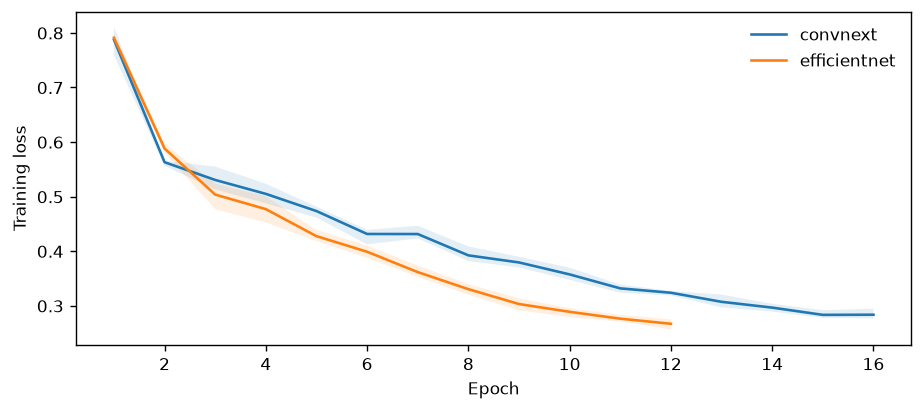

In [8]:
ranking, selected = choose_refinement(dev, folds, oof_by_backbone, texture)
display(ranking.round(4))
print(f"Selected {selected['backbone']} with {selected['method']}, threshold {selected['threshold']:.4f}")
dev_scores = development_scores(dev, oof_by_backbone, texture, selected)
recall_cut, recall_dev_acc, recall_dev_bal, accuracy_margin = recall_sensitive_threshold(truth[dev], dev_scores)
print(f"Recall-sensitive cutoff {recall_cut:.4f} | development accuracy {recall_dev_acc:.2%} | "
      f"development balanced accuracy {recall_dev_bal:.2%}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for name, records in histories.items():
    stats = records.groupby("epoch")["loss"].agg(["mean", "min", "max"])
    ax.plot(stats.index, stats["mean"], label=name)
    ax.fill_between(stats.index, stats["min"], stats["max"], alpha=0.12)
ax.set(xlabel="Epoch", ylabel="Training loss")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Refit on the full development set

The fold models each saw 1,476 development images. After the first test result, the selected backbones were refit from ImageNet weights on all 1,968 development images using local contrast. The two comparisons use the refits alone and a 50/50 average of refit and fold scores for each backbone. The development calibrator, backbone weights, and accuracy cutoff stay fixed. All results below use the same test images.

In [9]:
fit_full_development(images_by_backbone, levels, types, dev, selected, run_dir)

convnext | 1,968 development images | 16 epochs
efficientnet | 1,968 development images | 12 epochs


## Test results

Ordinary accuracy counts all correct predictions. Balanced accuracy averages non-defect recall and defect recall. The reference runs used the same local test split. The paper used its own test split, so the paper comparison is descriptive.

As a secondary operating point for the fold ensemble, the notebook chooses the most balanced cutoff within one standard error of peak development accuracy. This follow-up was prompted by the first test pass and uses only development predictions to set the new cutoff.

In [10]:
fold_heads = score_fold_ensemble(images_by_backbone, types, run_dir, test_idx, selected)
texture_test = None
if selected["method"] == "Ordinal heads and texture":
    measurements = texture_matrix(test_idx)
    with threadpool_limits(limits=3):
        texture_test = np.mean([m.predict_proba(measurements)[:, 1] for m in texture_models], axis=0)
refit_heads = score_full_refits(images_by_backbone, types, run_dir, test_idx, selected, fold_heads)
blended_heads = {key: (1 - FULL_REFIT_BLEND) * fold_heads[key] + FULL_REFIT_BLEND * p
                 for key, p in refit_heads.items()}
fold_scores = apply_calibration(fold_heads, test_idx, selected, texture_models, texture_test)
scores = apply_calibration(blended_heads, test_idx, selected, texture_models, texture_test)
standalone = apply_calibration(refit_heads, test_idx, selected, texture_models, texture_test)

In [11]:
TARGET_NAMES = ("Non-defective", "Defective")


def test_metrics(y, scores, threshold):
    pred = (scores >= threshold).astype(int)
    report = classification_report(y, pred, labels=[0, 1], target_names=TARGET_NAMES,
                                   output_dict=True, zero_division=0)
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y, pred),
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "Non-defect recall": report["Non-defective"]["recall"],
        "Defect recall": report["Defective"]["recall"],
        "Defect precision": report["Defective"]["precision"],
        "Defect F1": f1_score(y, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y, scores),
    }


def show_confusions(y, predictions):
    names = list(predictions)
    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 3.65), squeeze=False)
    for ax, name in zip(axes[0], names):
        scores, cut = predictions[name]
        ConfusionMatrixDisplay(
            confusion_matrix(y, scores >= cut, labels=[0, 1]), display_labels=TARGET_NAMES,
        ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(name, fontsize=11)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Dataset label")
    fig.tight_layout()
    plt.show()

603/656 correct | accuracy 91.92% | balanced accuracy 87.74%
Defect recall 76.59% | defect precision 96.91% | ROC AUC 95.39%


,Accuracy,Balanced accuracy
Model,,
Paper-style baseline (earlier run),86.89%,86.47%
Three-model ensemble (earlier run),90.85%,88.29%
Fine-tuned fold ensemble,91.77%,87.63%
Fold ensemble with recall-sensitive cutoff,91.31%,87.83%
Full-development refit blend,91.92%,87.74%
Full-development refits,91.62%,87.65%
Published Table 13 benchmark,—,90.13%


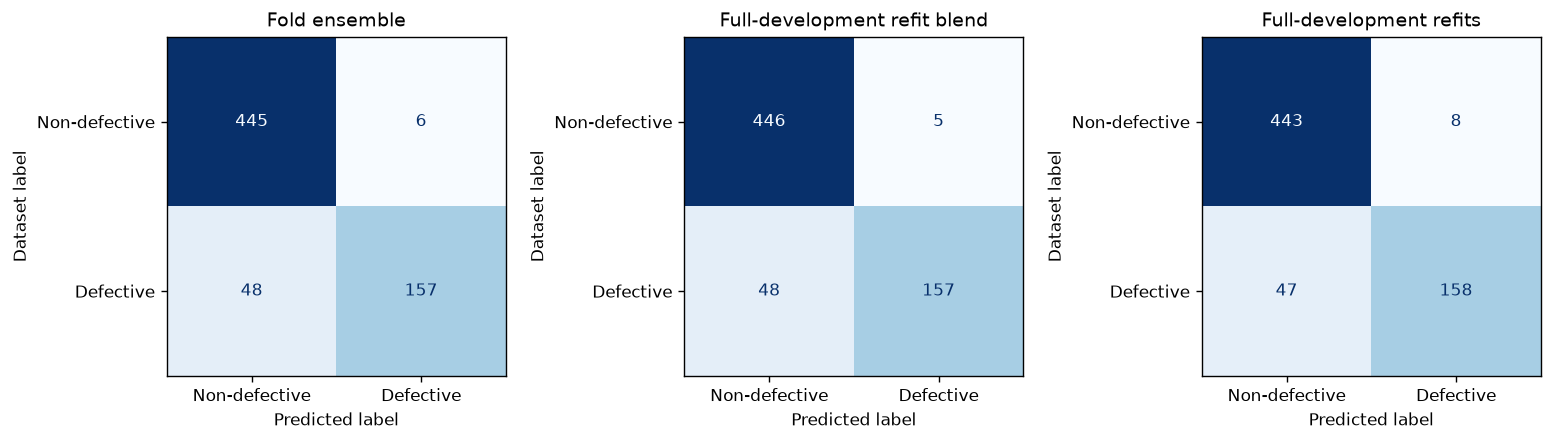

In [12]:
cut = selected["threshold"]
y_test = truth[test_idx]
result = test_metrics(y_test, scores, cut)
fold_result = test_metrics(y_test, fold_scores, cut)
recall_result = test_metrics(y_test, fold_scores, recall_cut)
standalone_result = test_metrics(y_test, standalone, cut)
decisions = (scores >= cut).astype(int)
correct = int((decisions == y_test).sum())
print(f"{correct}/{len(y_test)} correct | accuracy {result['Accuracy']:.2%} | "
      f"balanced accuracy {result['Balanced accuracy']:.2%}")
print(f"Defect recall {result['Defect recall']:.2%} | defect precision {result['Defect precision']:.2%} | "
      f"ROC AUC {result['ROC AUC']:.2%}")

comparison = pd.DataFrame(
    [("Paper-style baseline (earlier run)", 0.8689, 0.8647),
     ("Three-model ensemble (earlier run)", 0.9085, 0.8829),
     ("Fine-tuned fold ensemble", fold_result["Accuracy"], fold_result["Balanced accuracy"]),
     ("Fold ensemble with recall-sensitive cutoff", recall_result["Accuracy"], recall_result["Balanced accuracy"]),
     ("Full-development refit blend", result["Accuracy"], result["Balanced accuracy"]),
     ("Full-development refits", standalone_result["Accuracy"], standalone_result["Balanced accuracy"]),
     ("Published Table 13 benchmark", np.nan, 0.9013)],
    columns=["Model", "Accuracy", "Balanced accuracy"],
).set_index("Model")
display(comparison.apply(lambda col: col.map(lambda x: f"{x:.2%}" if pd.notna(x) else "—")))
show_confusions(y_test, {
    "Fold ensemble": (fold_scores, cut),
    "Full-development refit blend": (scores, cut),
    "Full-development refits": (standalone, cut),
})